## Project Name: Titanic Passenger Survival Analysis

</h2>Problem: Identifying the Factors That Influenced Passenger Survival on the Titanic</h2>

### Objectives
- Clean the dataset by handling missing values and duplicates
- Explore survival patterns by sex, class, age, and family size
- Calculate descriptive statistics and analyze correlations
- Visualize the findings and provide analytical recommendations

</h2>Importing Liberaries</h2>

In [3]:
import pandas as pd
import matplotlib.pyplot as plt 

</h2>Loading CSV</h2>

In [4]:
df = pd.read_csv(r"C:\Users\sisoa\Python\titanic.csv")

Checking Data & Nulls

In [5]:
print(df.shape) 
print(50*'-')
print(df.head())
print(50*'-') 
print(df.dtypes)
print(50*'-')


(891, 12)
--------------------------------------------------
   PassengerId  Survived  Pclass  \
0            1         0       3   
1            2         1       1   
2            3         1       3   
3            4         1       1   
4            5         0       3   

                                                Name     Sex   Age  SibSp  \
0                            Braund, Mr. Owen Harris    male  22.0      1   
1  Cumings, Mrs. John Bradley (Florence Briggs Th...  female  38.0      1   
2                             Heikkinen, Miss. Laina  female  26.0      0   
3       Futrelle, Mrs. Jacques Heath (Lily May Peel)  female  35.0      1   
4                           Allen, Mr. William Henry    male  35.0      0   

   Parch            Ticket     Fare Cabin Embarked  
0      0         A/5 21171   7.2500   NaN        S  
1      0          PC 17599  71.2833   C85        C  
2      0  STON/O2. 3101282   7.9250   NaN        S  
3      0            113803  53.1000  C123      

In [6]:
print(df.info())
print(50*'-') 

<class 'pandas.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    str    
 4   Sex          891 non-null    str    
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    str    
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    str    
 11  Embarked     889 non-null    str    
dtypes: float64(2), int64(5), str(5)
memory usage: 83.7 KB
None
--------------------------------------------------


In [7]:
df.duplicated().sum()

np.int64(0)

In [8]:
df.isnull().sum()

PassengerId      0
Survived         0
Pclass           0
Name             0
Sex              0
Age            177
SibSp            0
Parch            0
Ticket           0
Fare             0
Cabin          687
Embarked         2
dtype: int64

### Notes:
- Cabin has 687 missing values (77.1%)
- Age has 177 missing values (19.9%)
- Embarked has 2 missing values (0.2%)

# Data Cleaning

In [9]:
df_clean = df.copy()

In [10]:
most_common = df_clean["Embarked"].mode()[0]
df_clean["Embarked"] = df_clean["Embarked"].fillna(most_common)
df_clean["Embarked"].isnull().sum()

np.int64(0)

In [11]:
print(df_clean.groupby(["Pclass", "Sex"])["Age"].median())

Pclass  Sex   
1       female    35.0
        male      40.0
2       female    28.0
        male      30.0
3       female    21.5
        male      25.0
Name: Age, dtype: float64


In [12]:
df_clean["Age"] = df_clean["Age"].fillna(
    df_clean.groupby(["Pclass", "Sex"])["Age"].transform("median").round()
)
print(df_clean["Age"].isnull().sum())

0


In [13]:
df_clean["HasCabin"] = df_clean["Cabin"].notnull().map({True: "Yes", False: "No"})
df_clean["Cabin"] = df_clean["Cabin"].fillna("Other")

print(df_clean["HasCabin"].value_counts())
print(df_clean["Cabin"].isnull().sum())

HasCabin
No     687
Yes    204
Name: count, dtype: int64
0


In [14]:
df_clean["AgeGroup"] = pd.cut(
    df_clean["Age"],
    bins=[0, 12, 18, 35, 60, 100],
    labels=["Child", "Teen", "Young Adult", "Adult", "Senior"],
    include_lowest=True)
df_clean["FamilySize"] = df_clean["SibSp"] + df_clean["Parch"] + 1
df_clean["IsAlone"] = (df_clean["FamilySize"] == 1).astype(int)


## Data Cleaning Summary

| Column | What we did |
|---|---|
| PassengerId | Unique identifier. No missing values, no changes. |
| Survived | Target variable (0 = did not survive, 1 = survived). No missing values, kept as 0/1. |
| Pclass | Ticket class (1, 2, 3). No missing values, values checked and valid. |
| Name | Passenger name. No missing values, kept for reference only. |
| Sex | Passenger gender. No missing values, values checked (male/female). |
| Age | 177 missing values filled with the median age of each Pclass and Sex group, rounded to whole years. |
| SibSp | Siblings/spouses aboard. No missing values, no changes. |
| Parch | Parents/children aboard. No missing values, no changes. |
| Ticket | Ticket number. No missing values, kept for reference only. |
| Fare | Ticket price. No missing values, kept as float (monetary value). |
| Cabin | 687 missing values (77%) filled with "Other" to avoid inventing cabin numbers. |
| Embarked | 2 missing values filled with the most common port (mode). |
| HasCabin (new) | Yes/No flag created before filling Cabin, showing whether a cabin was recorded. |
| FamilySize (new) | SibSp + Parch + 1, the total family members aboard including the passenger. |
| IsAlone (new) | 1 if FamilySize equals 1 (travelling alone), otherwise 0. |
| AgeGroup (new) | Age grouped into Child, Teen, Young Adult, Adult, and Senior. |

### Cleaning Result
- No duplicates found
- All missing values handled (Age, Cabin, Embarked)
- 4 new columns created: HasCabin, FamilySize, IsAlone, AgeGroup
- Final dataset: 891 rows and 16 columns, with 0 missing values

# Data Analysis

</h2>1. Overall Survival</h2>

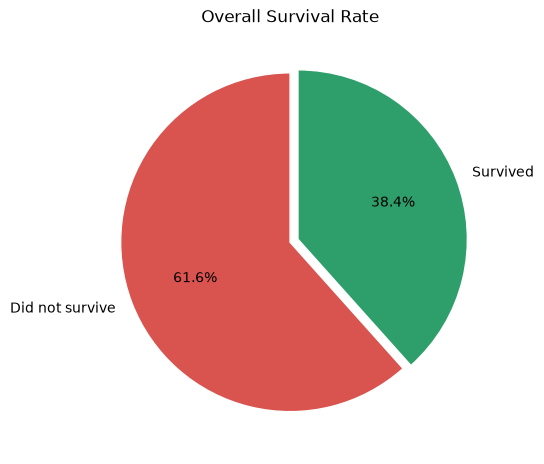

In [23]:
counts = df_clean["Survived"].value_counts().sort_index()
fig, ax = plt.subplots(figsize=(5.5, 5.5))
ax.pie(
    counts.values,
    labels=["Did not survive", "Survived"],
    colors=["#d9534f", "#2e9e6b"],
    autopct="%1.1f%%",
    startangle=90,
    explode=(0, 0.05),
    wedgeprops={"edgecolor": "white"}
)
ax.set_title("Overall Survival Rate")
plt.show()

</h2>2. Survivals by Sex & Class

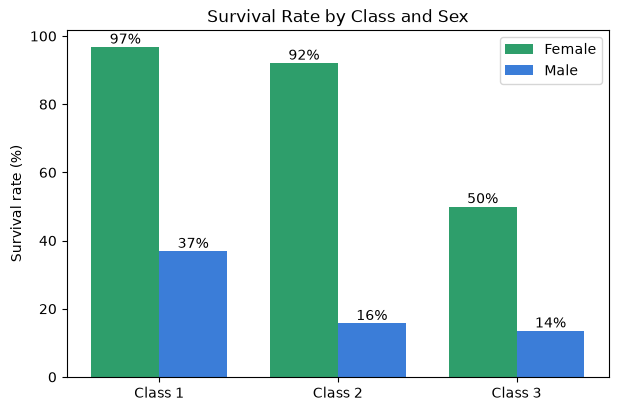

In [17]:
piv = df_clean.pivot_table(values="Survived", index="Pclass", columns="Sex")
piv = piv * 100
x = range(len(piv)); w = 0.38
fig, ax = plt.subplots(figsize=(7, 4.5))
b1 = ax.bar([i - w/2 for i in x], piv["female"], w, label="Female", color="#2e9e6b")
b2 = ax.bar([i + w/2 for i in x], piv["male"], w, label="Male", color="#3b7dd8")
ax.bar_label(b1, fmt="%.0f%%"); ax.bar_label(b2, fmt="%.0f%%")
ax.set_xticks(list(x)); ax.set_xticklabels([f"Class {c}" for c in piv.index])
ax.set_ylabel("Survival rate (%)"); ax.set_title("Survival Rate by Class and Sex")
ax.legend()
plt.show()

</h2>3. Age Analysis

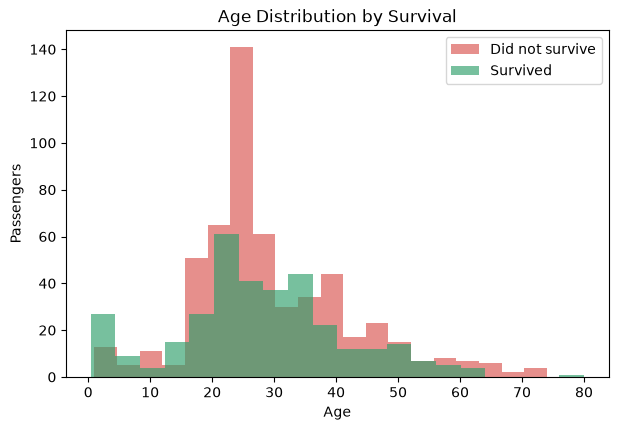

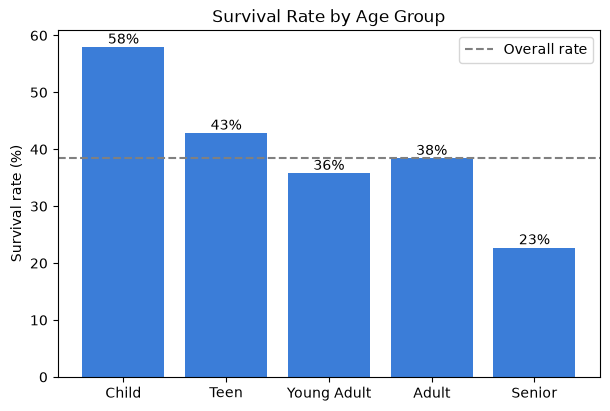

In [18]:
fig, ax = plt.subplots(figsize=(7, 4.5))
ax.hist(df_clean.loc[df_clean["Survived"] == 0, "Age"], bins=20, alpha=0.65, color="#d9534f", label="Did not survive")
ax.hist(df_clean.loc[df_clean["Survived"] == 1, "Age"], bins=20, alpha=0.65, color="#2e9e6b", label="Survived")
ax.set_xlabel("Age"); ax.set_ylabel("Passengers")
ax.set_title("Age Distribution by Survival"); ax.legend()
plt.show()

by_age = df_clean.groupby("AgeGroup", observed=True)["Survived"].mean() * 100
fig, ax = plt.subplots(figsize=(7, 4.5))
bars = ax.bar(by_age.index.astype(str), by_age.values, color="#3b7dd8")
ax.bar_label(bars, fmt="%.0f%%")
ax.axhline(df_clean["Survived"].mean() * 100, color="gray", ls="--", label="Overall rate")
ax.set_ylabel("Survival rate (%)"); ax.set_title("Survival Rate by Age Group"); ax.legend()
plt.show()

</h2>4. Age vs Fare, colored by survival

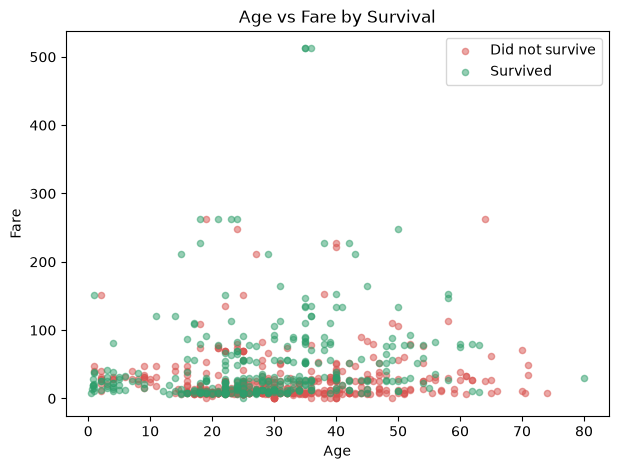

In [29]:
fig, ax = plt.subplots(figsize=(7, 5))
for s, color, label in [(0, "#d9534f", "Did not survive"), (1, "#2e9e6b", "Survived")]:
    sub = df_clean[df_clean["Survived"] == s]
    ax.scatter(sub["Age"], sub["Fare"], c=color, alpha=0.5, s=20, label=label)
ax.set_xlabel("Age"); ax.set_ylabel("Fare")
ax.set_title("Age vs Fare by Survival"); ax.legend()
plt.show()

</h2>5. Correlation Analysis

Sex           0.54
Pclass       -0.34
HasCabin      0.32
Fare          0.26
IsAlone      -0.20
Parch         0.08
Age          -0.06
SibSp        -0.04
FamilySize    0.02
Name: Survived, dtype: float64


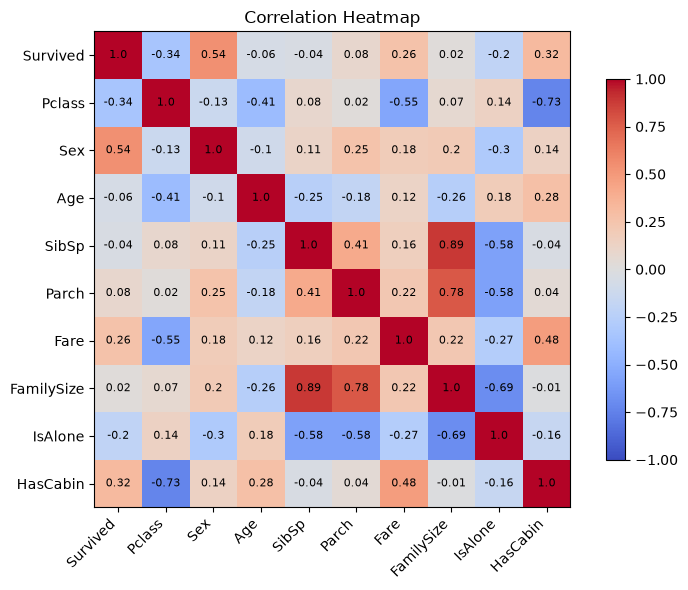

In [21]:
df_corr = df_clean.copy()
df_corr["Sex"] = df_corr["Sex"].map({"male": 0, "female": 1})
df_corr["HasCabin"] = df_corr["HasCabin"].map({"No": 0, "Yes": 1})
cols = ["Survived", "Pclass", "Sex", "Age", "SibSp", "Parch",
        "Fare", "FamilySize", "IsAlone", "HasCabin"]
corr = df_corr[cols].corr().round(2)
print(corr["Survived"].drop("Survived").sort_values(key=abs, ascending=False))

fig, ax = plt.subplots(figsize=(8, 6))
im = ax.imshow(corr, cmap="coolwarm", vmin=-1, vmax=1)
ax.set_xticks(range(len(cols))); ax.set_yticks(range(len(cols)))
ax.set_xticklabels(cols, rotation=45, ha="right"); ax.set_yticklabels(cols)
for i in range(len(cols)):
    for j in range(len(cols)):
        ax.text(j, i, corr.iloc[i, j], ha="center", va="center", fontsize=8)
fig.colorbar(im, ax=ax, shrink=0.8)
ax.set_title("Correlation Heatmap")
plt.tight_layout(); plt.show()

</h2>6. Fare Analysis

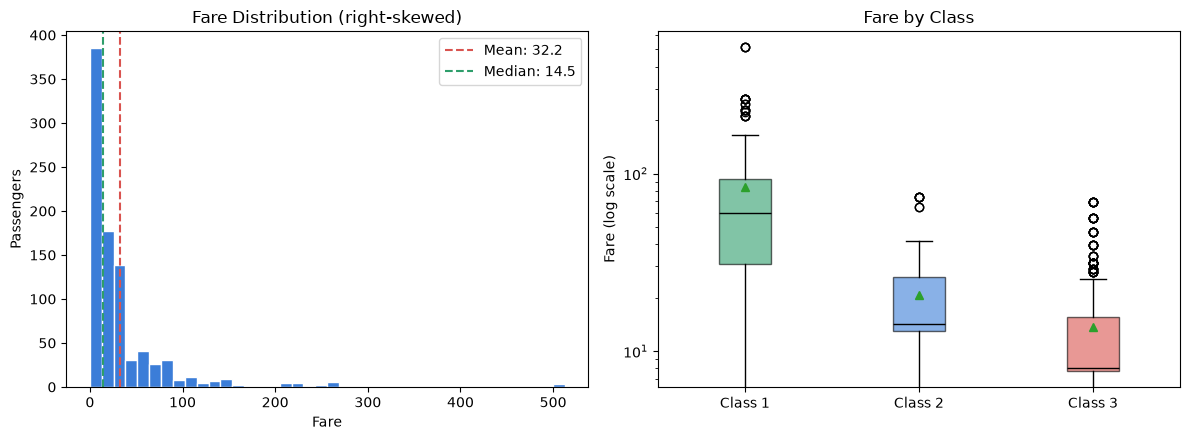

In [24]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

# Left: histogram with mean and median
axes[0].hist(df_clean["Fare"], bins=40, color="#3b7dd8", edgecolor="white")
axes[0].axvline(df_clean["Fare"].mean(), color="#d9534f", ls="--", label=f"Mean: {df_clean['Fare'].mean():.1f}")
axes[0].axvline(df_clean["Fare"].median(), color="#2e9e6b", ls="--", label=f"Median: {df_clean['Fare'].median():.1f}")
axes[0].set_xlabel("Fare")
axes[0].set_ylabel("Passengers")
axes[0].set_title("Fare Distribution (right-skewed)")
axes[0].legend()

# Right: boxplot by class, log scale
classes = sorted(df_clean["Pclass"].unique())
data = [df_clean.loc[df_clean["Pclass"] == c, "Fare"] for c in classes]
bp = axes[1].boxplot(data, tick_labels=[f"Class {c}" for c in classes],
                     patch_artist=True, showmeans=True,
                     medianprops=dict(color="black"))
for patch, color in zip(bp["boxes"], ["#2e9e6b", "#3b7dd8", "#d9534f"]):
    patch.set_facecolor(color)
    patch.set_alpha(0.6)
axes[1].set_yscale("log")
axes[1].set_ylabel("Fare (log scale)")
axes[1].set_title("Fare by Class")

plt.tight_layout()
plt.show()

</h2>7. survival by port of embarkation

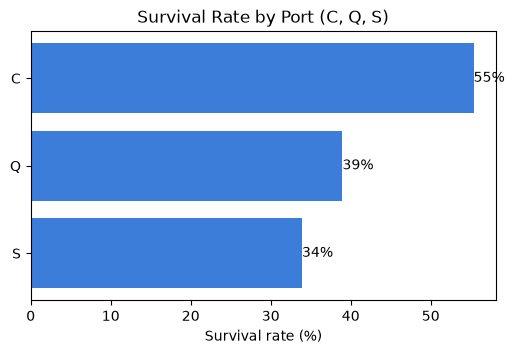

In [26]:
rate = (df_clean.groupby("Embarked")["Survived"].mean() * 100).sort_values()
fig, ax = plt.subplots(figsize=(6, 3.5))
bars = ax.barh(rate.index, rate.values, color="#3b7dd8")
ax.bar_label(bars, fmt="%.0f%%")
ax.set_xlabel("Survival rate (%)"); ax.set_title("Survival Rate by Port (C, Q, S)")
plt.show()

</h2>8. Passengers by Class

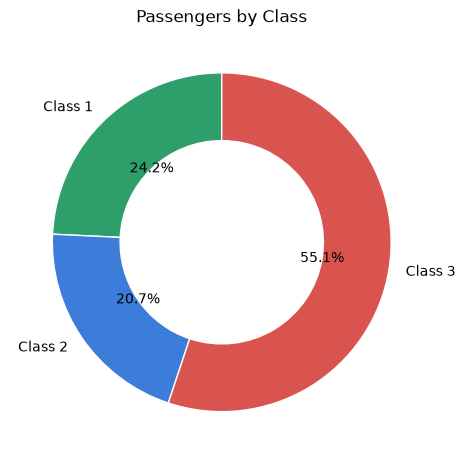

In [27]:
cls = df_clean["Pclass"].value_counts().sort_index()
fig, ax = plt.subplots(figsize=(5.5, 5.5))
ax.pie(cls.values, labels=[f"Class {c}" for c in cls.index], autopct="%1.1f%%",
       colors=["#2e9e6b", "#3b7dd8", "#d9534f"], startangle=90,
       wedgeprops={"width": 0.4, "edgecolor": "white"})
ax.set_title("Passengers by Class")
plt.show()

## Insights & Recommendations

### Key Insights

**1. Overall Survival**
Only 38.4% of the 891 passengers survived (342 survived, 549 did not). Most passengers died.

**2. Survival by Sex and Class**
- Sex was the strongest factor: women survived at 74.2% vs 18.9% for men.
- Class also mattered: survival was 63.0% in 1st class, 47.3% in 2nd class and 24.2% in 3rd class.
- Class changed the effect of sex. Women in 1st and 2nd class survived at 96.8% and 92.1%, but 3rd-class women only at 50.0%. Men survived at 36.9% in 1st class, 15.7% in 2nd and 13.5% in 3rd.

**3. Age Analysis**
- Children (12 and under) had the highest survival rate at 58.0%, followed by teens at 42.9%.
- Young adults (35.8%) and adults (38.4%) were close to the overall rate, and seniors had the lowest rate at 22.7% (only 22 passengers).
- Most passengers were young adults (514 of 891). The median age is 26, and ages range from 0.42 to 80.
- Age was only weakly related to survival overall (correlation -0.06), so its effect is much smaller than sex or class.

**4. Age vs Fare (colored by survival)**
- Survivors average a much higher fare (48.40) than non-survivors (22.12), while average age is similar (28.2 vs 29.8).
- Most low-fare passengers did not survive, and survival rises with fare. Of the 20 passengers who paid over 200, 70% survived.
- Age alone shows no clear pattern. Fare separates the two groups better.

**5. Fare Analysis**
- Fare is strongly right-skewed (skewness 4.79): the mean (32.20) is much higher than the median (14.45), because a few very expensive tickets pull the average up.
- The median fare differs hugely by class: 60.29 in 1st class, 14.25 in 2nd and 8.05 in 3rd. Fare and class are strongly linked (correlation -0.55).
- 116 passengers were fare outliers (above 65.63). They are real first-class tickets, so they were kept. 15 passengers have a fare of 0.

**6. Survival by Port of Embarkation**
- Cherbourg (C) had the highest survival at 55.4%, compared with 39.0% for Queenstown (Q) and 33.9% for Southampton (S).
- Class explains much of this: 50.6% of Cherbourg passengers were 1st class, vs 20.0% at Southampton.
- Class does not explain everything, though. Queenstown was 93.5% 3rd class yet survived better than Southampton, so the port effect is not only a class effect.

**7. Passengers by Class**
3rd class made up the majority (491 passengers, 55.1%), while 1st class had 216 (24.2%) and 2nd class 184 (20.7%). The largest class had the lowest survival rate, which explains the low overall rate.

**8. Correlation Analysis**
- Sex has the strongest correlation with survival (+0.54, with female coded as 1).
- Pclass is negative (-0.34): a lower class number (better class) goes with higher survival.
- HasCabin (+0.32) and Fare (+0.26) are moderately positive, and both overlap with 1st class: 176 of the 204 passengers with a recorded cabin were in 1st class.
- IsAlone is weakly negative (-0.20): solo travellers survived at 30.4% vs 50.6% for those with family.
- Age (-0.06), SibSp (-0.04), Parch (+0.08) and FamilySize (+0.02) have almost no linear relationship with survival.
- FamilySize is built from SibSp and Parch, so those relationships are partly expected.

### Overall Conclusion
Survival followed a clear pattern: **women, first-class passengers and higher-paying passengers were much more likely to survive**. Sex was the strongest single factor and class was second. Children also had an advantage. Port and family status had smaller effects, and several of them are partly explained by class.

### Recommendations
1. **Equal evacuation access:** emergency routes, signage and boat access should serve every deck and ticket class equally, because survival should not depend on ticket price.
2. **Protect the most at-risk group:** 3rd-class men survived at only 13.5%. Safety planning should include assigned crew assistance for lower-class passengers.
3. **Support vulnerable passengers:** travellers who are alone and the elderly had the lowest survival rates and need dedicated help during evacuation.
4. **Base procedures on need, not on sex or status:** "women and children first" helped many, but most men had little chance, especially in 2nd and 3rd class.
5. **Improve data collection:** Age was missing for 19.9% of passengers and Cabin for 77.1%. Complete passenger records would give more reliable safety analysis.
6. **Next analytical step:** build a predictive model (such as logistic regression or a decision tree) using Sex, Pclass, Fare and Age, and test how accurately it predicts survival.